# Project 2 — Cats vs Dogs Classification Using CNN

This project trains a convolutional neural network with **exactly three convolutional layers** to distinguish cat and dog photographs. The training code runs on a CPU, and the notebook is compatible with Google Colab and Kaggle.

**About the saved outputs:** The outputs currently embedded in this notebook come from a small **offline test using generated shapes**, not cat/dog photographs. They verify that the code runs; they are **not genuine Cats vs Dogs accuracy results**. When you run all the cells with the real dataset, the outputs will be replaced with your actual training results.

## 1. Imports and settings

The notebook uses PyTorch, Pillow, Matplotlib and Scikit-learn. Colab normally includes these libraries.

In [1]:
import os
import random
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image, ImageOps
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from torch import nn
from torch.utils.data import Dataset, DataLoader

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(min(4, os.cpu_count() or 1))
preview = os.getenv('WORKSHOP_PREVIEW') == '1'
print('Device: CPU')
print('CPU threads:', torch.get_num_threads())
if preview:
    print('OFFLINE PREVIEW ONLY: generated shapes, not real cat and dog photos')

Device: CPU
CPU threads: 4
OFFLINE PREVIEW ONLY: generated shapes, not real cat and dog photos


## 2. Load the images

In Kaggle, attach a Cats vs Dogs dataset using **Add Input**. In Colab, the notebook downloads the smaller TensorFlow cats-and-dogs archive automatically, provided internet access is available. The offline preview is only used when the special test setting is enabled.

In [2]:
def make_preview_images():
    folder = Path('/tmp/cnn_offline_preview')
    rng = np.random.default_rng(seed)
    for group, count in [('train', 18), ('test', 6)]:
        for label, name in [(0, 'cats'), (1, 'dogs')]:
            target = folder / group / name
            target.mkdir(parents=True, exist_ok=True)
            for i in range(count):
                array = rng.integers(20, 75, (96, 96, 3), dtype=np.uint8)
                if label == 0:
                    array[18:77, 15:62, 0] = 220
                    array[18:77, 15:62, 1:] = 30
                else:
                    array[20:78, 33:83, 2] = 220
                    array[20:78, 33:83, :2] = 30
                Image.fromarray(array).save(target / f'{name}.{i}.png')
    return folder


def find_data():
    if preview:
        return make_preview_images()
    kaggle = Path('/kaggle/input')
    if kaggle.exists():
        for folder in sorted(kaggle.iterdir()):
            if any(p.name.lower() in {'cats', 'dogs'} for p in folder.rglob('*') if p.is_dir()):
                return folder
    data_folder = Path('workshop_data')
    data_folder.mkdir(exist_ok=True)
    extracted = data_folder / 'cats_and_dogs_filtered'
    if extracted.exists():
        return extracted
    archive = data_folder / 'cats_and_dogs_filtered.zip'
    url = 'https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip'
    if not archive.exists():
        print('Downloading Cats vs Dogs images...')
        try:
            urlretrieve(url, archive)
        except Exception as error:
            raise RuntimeError('Dataset download failed. In Kaggle, attach a Cats vs Dogs dataset through Add Input. In Colab, check runtime internet access.') from error
    with zipfile.ZipFile(archive) as z:
        z.extractall(data_folder)
    return extracted

folder = find_data()
print('Dataset folder:', folder)


def label_for(path):
    folders = {piece.lower() for piece in path.parts[:-1]}
    name = path.stem.lower()
    if 'cats' in folders or 'cat' in folders or name.startswith(('cat.', 'cat_', 'cat-')):
        return 0
    if 'dogs' in folders or 'dog' in folders or name.startswith(('dog.', 'dog_', 'dog-')):
        return 1
    return None


def split_for(path):
    folders = {part.lower() for part in path.parts}
    if folders & {'test', 'test_set', 'testing', 'testing_set', 'validation', 'valid'}:
        return 'test'
    return 'train'

all_files = {'train': {0: [], 1: []}, 'test': {0: [], 1: []}}
for path in folder.rglob('*'):
    if path.is_file() and path.suffix.lower() in {'.jpg', '.jpeg', '.png'}:
        label = label_for(path)
        if label is not None:
            all_files[split_for(path)][label].append(path)

if not all(all_files['train'].values()):
    raise RuntimeError('Could not find the training cat and dog images. Check the dataset folder structure.')
print('Images found:', {part: {('cat' if label == 0 else 'dog'): len(paths) for label, paths in rows.items()} for part, rows in all_files.items()})

Dataset folder: /tmp/cnn_offline_preview
Images found: {'train': {'cat': 18, 'dog': 18}, 'test': {'cat': 6, 'dog': 6}}


## 3. Prepare training, validation and test data

Images are resized to 96 × 96 pixels. We split the training images into separate training and validation sets. If the dataset has a test folder, that is kept for the final evaluation.

Train: 30 | Validation: 6 | Test: 12


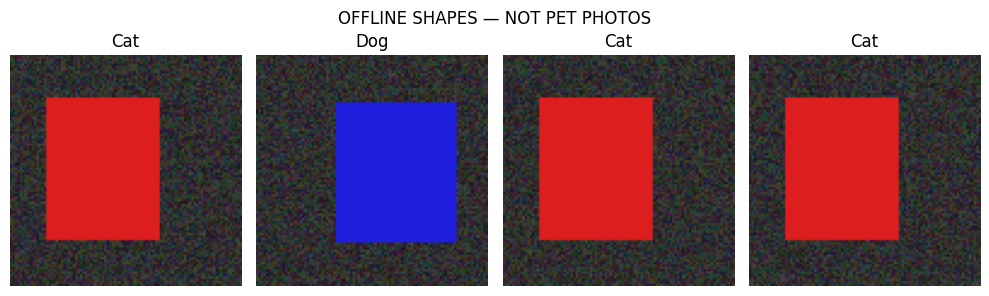

In [3]:
rng = random.Random(seed)
train_files, val_files, test_files = [], [], []
real_test = all(bool(all_files['test'][label]) for label in (0, 1))
max_train = 25 if preview else 700
max_test = 10 if preview else 250

for label in (0, 1):
    files = sorted(all_files['train'][label])
    rng.shuffle(files)
    files = files[:max_train]
    if len(files) < 5:
        raise RuntimeError('Not enough images for training and validation.')
    val_count = max(2, int(0.2 * len(files)))
    train_files.extend((p, label) for p in files[val_count:])
    val_files.extend((p, label) for p in files[:val_count])
    if real_test:
        held_out = sorted(all_files['test'][label])
        rng.shuffle(held_out)
        test_files.extend((p, label) for p in held_out[:max_test])

if not real_test:
    for label in (0, 1):
        subset = [(p, y) for p, y in train_files if y == label]
        count = max(1, int(0.15 * len(subset)))
        test_files.extend(subset[:count])
        train_files = [item for item in train_files if item not in subset[:count]]

rng.shuffle(train_files)
rng.shuffle(val_files)
rng.shuffle(test_files)
print('Train:', len(train_files), '| Validation:', len(val_files), '| Test:', len(test_files))

class PetImages(Dataset):
    def __init__(self, files, train=False):
        self.files = files
        self.train = train

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        path, label = self.files[index]
        with Image.open(path) as image:
            image = ImageOps.exif_transpose(image).convert('RGB').resize((96, 96))
            if self.train and random.random() < 0.5:
                image = ImageOps.mirror(image)
            pixels = np.asarray(image, dtype=np.float32) / 255.0
        return torch.from_numpy(pixels.copy()).permute(2, 0, 1), label

train_loader = DataLoader(PetImages(train_files, train=True), batch_size=24, shuffle=True)
val_loader = DataLoader(PetImages(val_files), batch_size=24)
test_loader = DataLoader(PetImages(test_files), batch_size=24)

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, (path, label) in zip(axes, train_files[:4]):
    ax.imshow(Image.open(path).convert('RGB'))
    ax.set_title('Cat' if label == 0 else 'Dog')
    ax.axis('off')
plt.suptitle('OFFLINE SHAPES — NOT PET PHOTOS' if preview else 'Training images')
plt.tight_layout()
plt.show()

## 4. Build a CNN with three convolutional layers

In [4]:
class PetCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 12, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(12, 24, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(24, 48, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(48 * 4 * 4, 96),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(96, 2)
        )

    def forward(self, images):
        return self.classifier(self.features(images))

model = PetCNN()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters()))

PetCNN(
  (features): Sequential(
    (0): Conv2d(3, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(12, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(24, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=768, out_features=96, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=96, out_features=2, bias=True)
  )
)
Trainable parameters: 87386


## 5. Train and save the best model

The real run uses up to six epochs, with early stopping if validation loss stops improving. The offline test runs only two epochs.

In [5]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    count, correct, loss_sum = 0, 0, 0.0
    for images, labels in loader:
        logits = model(images)
        loss_sum += loss_fn(logits, labels).item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
        count += len(labels)
    return loss_sum / count, correct / count

output_dir = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
output_dir.mkdir(exist_ok=True)
model_path = output_dir / 'cnn_cats_vs_dogs.pt'
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_loss, patience = float('inf'), 0

epochs = 2 if preview else 6
for epoch in range(1, epochs + 1):
    model.train()
    correct, count, total_loss = 0, 0, 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        logits = model(images)
        loss = loss_fn(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
        count += len(labels)
    train_loss, train_acc = total_loss / count, correct / count
    val_loss, val_acc = evaluate(val_loader)
    for key, value in zip(history, (train_loss, val_loss, train_acc, val_acc)):
        history[key].append(value)
    print(f'Epoch {epoch}/{epochs} | Train accuracy {train_acc:.1%} | Validation accuracy {val_acc:.1%}')
    if val_loss < best_loss:
        best_loss, patience = val_loss, 0
        torch.save(model.state_dict(), model_path)
    else:
        patience += 1
        if patience >= 2:
            break

model.load_state_dict(torch.load(model_path, map_location='cpu', weights_only=True))
print('Saved weights to:', model_path)
if preview:
    print('These scores are from GENERATED SHAPES ONLY, not real animal images.')

Epoch 1/2 | Train accuracy 50.0% | Validation accuracy 50.0%
Epoch 2/2 | Train accuracy 63.3% | Validation accuracy 100.0%
Saved weights to: outputs/cnn_cats_vs_dogs.pt
These scores are from GENERATED SHAPES ONLY, not real animal images.


## 6. Results and sample predictions

Accuracy, classification metrics and the confusion matrix are calculated on held-out examples. The saved offline preview only demonstrates that the evaluation code works.

Test loss: 0.6599 | Test accuracy: 100.0%
TEST ONLY — scores are NOT Cats vs Dogs project results.
              precision    recall  f1-score   support

         Cat       1.00      1.00      1.00         6
         Dog       1.00      1.00      1.00         6

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12



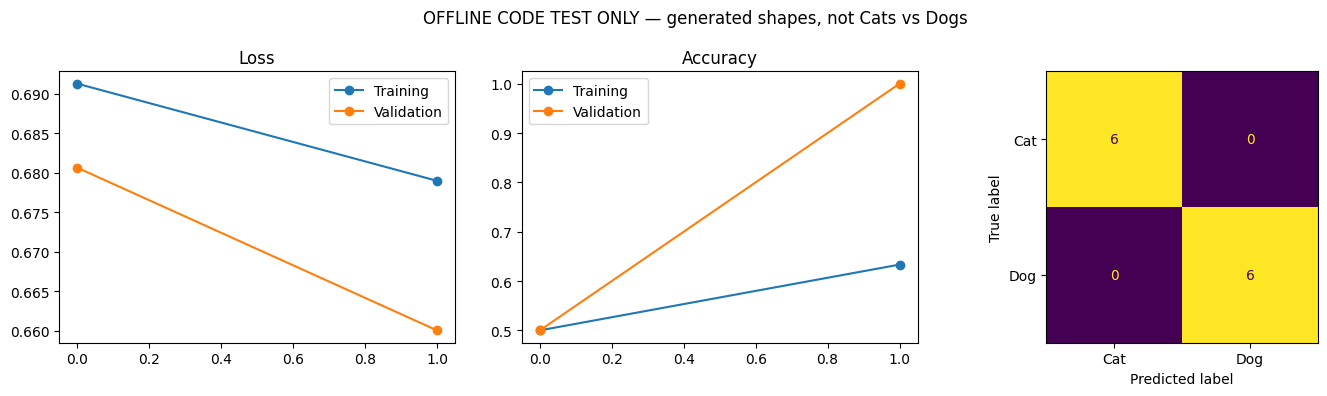

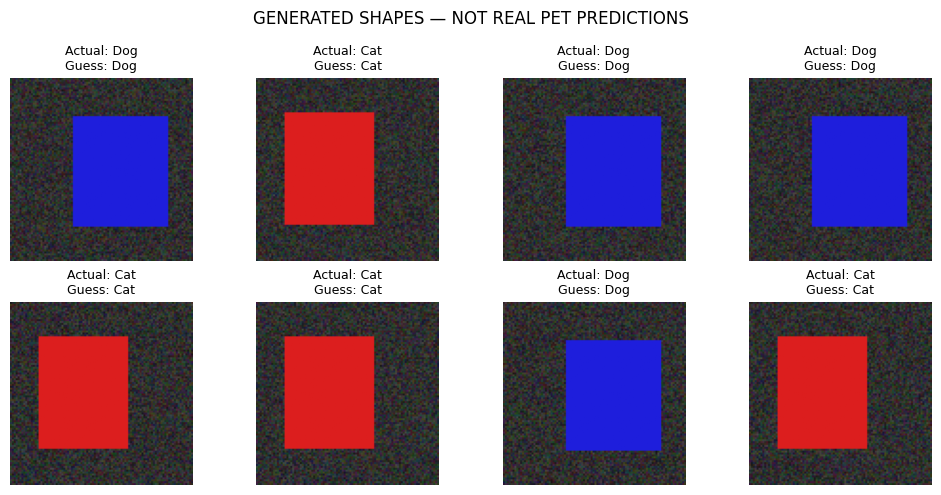

In [6]:
test_loss, test_accuracy = evaluate(test_loader)
print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.1%}')
if preview:
    print('TEST ONLY — scores are NOT Cats vs Dogs project results.')

actual, predicted = [], []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        actual.extend(labels.tolist())
        predicted.extend(model(images).argmax(1).tolist())

print(classification_report(actual, predicted, labels=[0, 1], target_names=['Cat', 'Dog'], zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(history['train_loss'], marker='o', label='Training')
axes[0].plot(history['val_loss'], marker='o', label='Validation')
axes[0].set_title('Loss')
axes[0].legend()
axes[1].plot(history['train_acc'], marker='o', label='Training')
axes[1].plot(history['val_acc'], marker='o', label='Validation')
axes[1].set_title('Accuracy')
axes[1].legend()
ConfusionMatrixDisplay.from_predictions(actual, predicted, labels=[0, 1], display_labels=['Cat', 'Dog'], ax=axes[2], colorbar=False)
if preview:
    fig.suptitle('OFFLINE CODE TEST ONLY — generated shapes, not Cats vs Dogs')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
with torch.no_grad():
    for ax, (path, label) in zip(axes.flat, test_files[:8]):
        picture, _ = PetImages([(path, label)])[0]
        guess = model(picture.unsqueeze(0)).argmax(1).item()
        ax.imshow(picture.permute(1, 2, 0))
        ax.set_title(f'Actual: {"Cat" if label == 0 else "Dog"}\nGuess: {"Cat" if guess == 0 else "Dog"}', fontsize=9)
        ax.axis('off')
for ax in list(axes.flat)[min(8, len(test_files)):]:
    ax.axis('off')
plt.suptitle('GENERATED SHAPES — NOT REAL PET PREDICTIONS' if preview else 'Sample predictions')
plt.tight_layout()
plt.show()

## What to upload to GitHub

Save the executed notebook (`.ipynb`) and the project README. The notebook includes its plots and results. Do not push downloaded image datasets or `.pt` weights into a normal GitHub repository. Run this notebook on the **real dataset** first if you want to report legitimate model accuracy.